In [1]:
import sys
print(sys.executable)

c:\Users\harish\Desktop\Ann_Project\Ann_env\Scripts\python.exe


### 1. Import Libraries

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)





### 2. Load Dataset

In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.head())
## print(df.shape)


   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [4]:
print(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### 3. Data Cleaning

In [5]:
# Remove Customer ID
# df.drop("customerID", axis=1, inplace=True)

# Convert TotalChanges into numeric 
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# handling missing values
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


### 4. Separate Features and Target

In [6]:
X = df.drop("Churn" ,axis=1)

y = df["Churn"].map({"Yes":1, "No":0})

print(X.head())
print(y.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No        

### 5. Identify Numerical and categorical Columns 

In [7]:
numerical_columns = X.select_dtypes(
    include=["int64","float64"]
).columns

categorical_columns = X.select_dtypes(
    include=["object"]
 ).columns

print("Numerical :", numerical_columns)
print("Categorical :", categorical_columns)

Numerical : Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')
Categorical : Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod'],
      dtype='str')


C:\Users\harish\AppData\Local\Temp\ipykernel_21308\293958552.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


### 6. Encoding and Feature Scaling

In [8]:
preprocessor = ColumnTransformer(
      transformers=[
        ("num", StandardScaler(), numerical_columns),

        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_columns)
      ]
)

X = preprocessor.fit_transform(X)

print("Process shape:", X.shape)

Process shape: (7043, 7088)


### 7. Train Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (5634, 7088)
Testing: (1409, 7088)


### 8. Build ANN Archtecture

Our Ann will have
1. Input Layer
2. Three hidden layers
3. ReLu activation
4. Dropout
5. Sigmoid output layer

In [10]:
import tensorflow as tf
from tensorflow.keras.models import Sequential 

In [11]:

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),

    tf.keras.layers.Dense(64,activation="relu"),
    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(32,activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(16, activation="relu"),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

### 9. Compile Model

In [12]:
model.compile(

    optimizer="adam",

    loss="binary_crossentropy",

    metrics=[
        "accuracy",

        tf.keras.metrics.Precision(),
        tf.keras.metrics.Recall(),
        tf.keras.metrics.AUC()
    ]
)

### 10. Train the ANN Model

In [13]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(

    X_train,
    y_train,

    epochs = 100,

    batch_size = 32,

    validation_split = 0.2,

    callbacks=[early_stop],

    verbose=1
)


Epoch 1/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7504 - auc: 0.7792 - loss: 0.4979 - precision: 0.5283 - recall: 0.5842 - val_accuracy: 0.7453 - val_auc: 0.8222 - val_loss: 0.5464 - val_precision: 0.7857 - val_recall: 0.0373
Epoch 2/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8032 - auc: 0.8428 - loss: 0.4219 - precision: 0.6509 - recall: 0.5625 - val_accuracy: 0.7906 - val_auc: 0.8236 - val_loss: 0.4862 - val_precision: 0.6832 - val_recall: 0.3729
Epoch 3/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8194 - auc: 0.8645 - loss: 0.3933 - precision: 0.6942 - recall: 0.5750 - val_accuracy: 0.7862 - val_auc: 0.8202 - val_loss: 0.4445 - val_precision: 0.6205 - val_recall: 0.4712
Epoch 4/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8700 - auc: 0.9190 - loss: 0.3110 - precision: 0.8010 - recall: 0.6808 - val_accuracy: 0.7622 - val_auc: 0.7941 - val_loss: 0.4713 - val_precision: 0.5470 - val_recall: 0.5322
Epoch 5/100
141/141 ━━━━━━━━

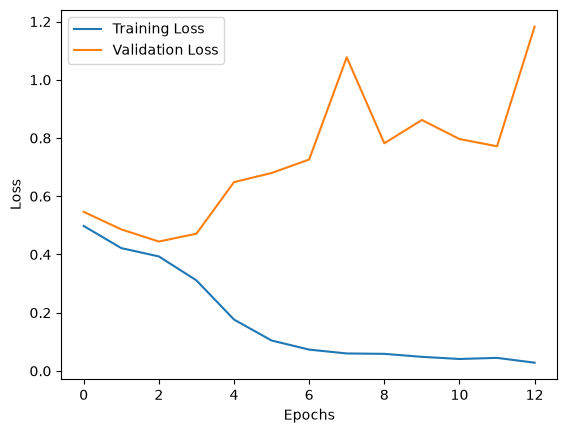

In [14]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### 11. evaluate Model

In [15]:
loss, accuracy, precision, recall,auc = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", loss)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("ROC-AUC:",auc)


45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7991 - auc: 0.8337 - loss: 0.4346 - precision: 0.6608 - recall: 0.5000
Test Loss: 0.43459880352020264
Accuracy: 0.7991483211517334
Precision: 0.6607773900032043
Recall: 0.5
ROC-AUC: 0.8337130546569824


### 12. Predictions and F1-score

In [16]:
y_probablity = model.predict(X_test)

y_pred = (y_probablity > 0.5).astype(int)

print("F1 Score:", f1_score(y_test,y_pred))
print("\nClassification Report : ")

print(classification_report(y_test,y_pred))

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
F1 Score: 0.5692541856925418

Classification Report : 
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1035
           1       0.66      0.50      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409



### 13. Confusion Matrix

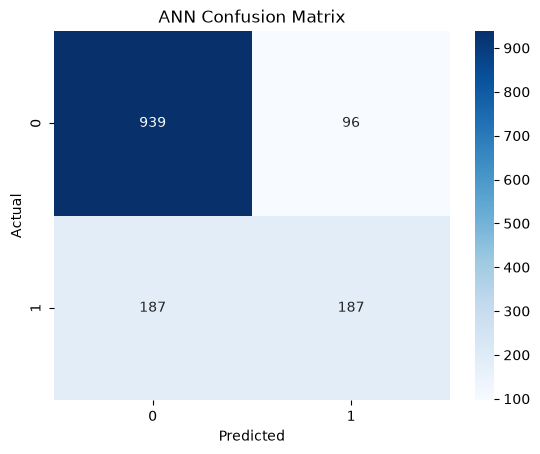

In [17]:
cm = confusion_matrix(y_test,y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ANN Confusion Matrix")

plt.show()


### Training vs Validation Loss

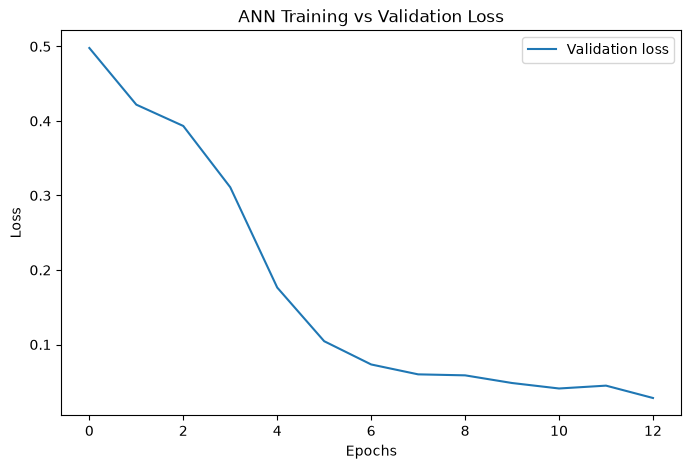

In [18]:
from cProfile import label
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Validation loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.title("ANN Training vs Validation Loss")

plt.legend()
plt.show()

### 15. Save Your Model

In [19]:
model.save("customer_churn_ann.keras")

import joblib

joblib.dump(
    preprocessor,
    "preprocessor.pkl"
)

['preprocessor.pkl']